# Tranform diffusion model

In [ ]:
model_type = "GRU"
data_set = "coastline"
model_name = f"ddpm_{model_type}_{data_set}_conv_adam_constant"
if data_set == 'coastline':
    length = 24
if data_set == 'open_ocean':
    length = 72
context_encoder_type = "conv"
K = 100

params = {
    "prediction_length": length,
    "dt": 1.0 / length,
    "model_type": model_type,
    "context_encoder_type": context_encoder_type,
    "K": K,}

model = CoDiTModel(name=model_name, params=params)

params, loss_list, val_loss_list, std = restore_checkpoint(model.ckpt_dir + 'final')
model.nn_params = params
model.std = std

In [30]:
export_path = '/mydata/adopt/christian/CoDiT/data/trained_models/'
model.export_trained_model(f'codit_{model_type}_{data_set}', export_path=export_path)

Exception: Model codit_GRU_coastline already exists in /mydata/adopt/christian/CoDiT/data/trained_models/codit_GRU_coastline. Please delete it or change the model name.

In [23]:
export_path = '/mydata/adopt/christian/CoDiT/data/trained_models/'
model_name = f'codit_{model_type}_{data_set}'
loaded_model = DiffusionModel.import_trained_model(model_name, import_path=export_path)

# Transform CNN

In [1]:
from codit.model_module.diffusion_model import CoDiTModel
from codit.model_module.conv_net import ConvNetModel
from codit.model_module.hycom_model import HycomModel
data_set = "open_ocean"  #'coastline'#

import_path = '/mydata/adopt/christian/CoDiT/data/trained_models/'

hycom_model = HycomModel(name='hycom', params={})
cnn_model = ConvNetModel.import_trained_model(f'cnn_{data_set}','/mydata/adopt/christian/CoDiT/data/trained_models/')
gru_model = CoDiTModel.import_trained_model(f'codit_GRU_{data_set}','/mydata/adopt/christian/CoDiT/data/trained_models/')
transformer_model = CoDiTModel.import_trained_model(f'codit_Transformer_{data_set}','/mydata/adopt/christian/CoDiT/data/trained_models/')

/myhome/mambaforge/envs/adopt/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [47]:
import os
from codit.data_module import config_funcs
from codit.data_module.dataset import OceanDataset
from codit.data_module import config_paths
config_path = os.path.join(
    config_paths.CONFIG_PATH,
    "open_ocean",
)
length = 72
files = os.listdir(config_path)
dataset_files = [f for f in files if f.endswith(".yml")]
val_datasets = []
for dataset_name in dataset_files:
    config = config_funcs.load_config(dataset_name.split(".")[0], config_path)
    if config["start_date"].year >= 2020 and os.path.exists(config["dataset_path"]):
        val_datasets.append(dataset_name)
        
data_name = val_datasets[1].split(".")[0]
#data_name = 'open_ocean_patch_9_year_2020'
config = config_funcs.load_config(data_name, config_path)
test_dataset = OceanDataset(config, length,)

In [55]:
start_position, start_time, times, interpolator, coordinates = test_dataset[101]
start_position, start_time, times, interpolator, coordinates = test_dataset[310]
#start_position, start_time, times, interpolator, coordinates = test_dataset[125]
#start_position, start_time, times, interpolator, coordinates = test_dataset[400]

In [56]:
pred_coord = {}
pred_coord['hycom'] = hycom_model.predict(
    start_position,
    start_time,
    72,
    interpolator,
    test_dataset,
)
print('CNN')
pred_coord['cnn'] = cnn_model.predict(
    start_position,
    start_time,
    72,
    interpolator,
    test_dataset,
    num_samples=100,
)
print('GRU')
pred_coord['gru'] = gru_model.predict(
    start_position,
    start_time,
    72,
    interpolator,
    test_dataset,
    num_samples=100,
)
print('Transformer')
pred_coord['transformer'] = transformer_model.predict(
    start_position,
    start_time,
    72,
    interpolator,
    test_dataset,
    num_samples=100,
)

CNN
GRU
Transformer


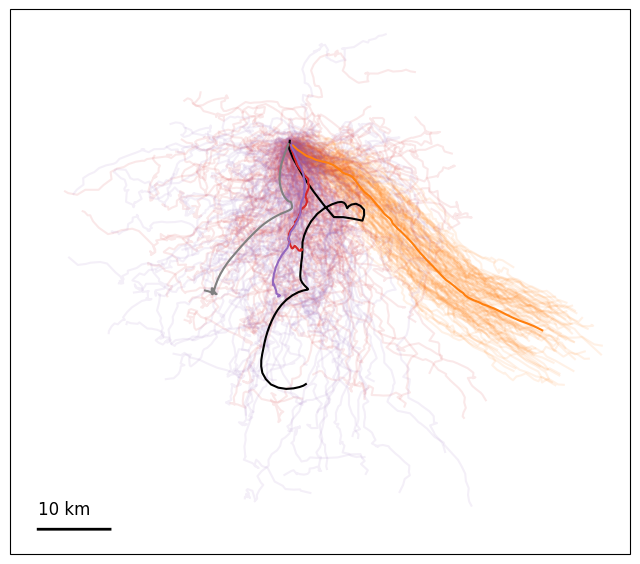

In [58]:
from matplotlib import pyplot as plt
from codit.data_module import inverse_haversine
from cartopy import crs as ccrs
import numpy as np
colors = {
    'hycom': 'gray',
    'cnn': 'C1',
    'gru': 'C3',
    'transformer': 'C4'
}
model_names = {
    'hycom': 'HYCOM',
    'cnn': 'CNN',
    'gru': 'CODIT GRU',
    'transformer': 'CODIT Transformer'
}

fig = plt.figure(figsize=(8, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.coastlines(resolution='10m')
ax.plot(coordinates[:, 1], coordinates[:, 0], 'k', label='True Path', zorder=9)
for model, color in colors.items():
    if model == 'hycom':
        ax.plot(pred_coord[model][...,1].T, pred_coord[model][...,0].T, color=color, label=model_names[model], zorder=9)
    else:
        ax.plot(np.nanmean(pred_coord[model][...,1], axis=0), np.nanmean(pred_coord[model][...,0], axis=0), color=color, label=model_names[model], zorder=9)
#plt.legend(frameon=False)

for model, color in colors.items():
    if model != 'hycom':
        ax.plot(pred_coord[model][...,1].T, pred_coord[model][...,0].T, color=color, alpha=0.1)

sb1 = ax.get_ylim()[0], ax.get_xlim()[0]
sb2 = inverse_haversine(sb1, 10e3, 90)
ax.set_aspect('equal', adjustable='box')
ax.plot((sb1[1], sb2[1]), (sb1[0], sb2[0]), 'k-', lw=2)
ax.text(sb1[1], sb1[0]+0.02, '10 km', fontsize=12)
plt.show()

In [51]:
pred_coord['transformer'][...,0]

Array([[-20.477695, -20.470398, -20.465183, ..., -20.252901, -20.246593,
        -20.240793],
       [-20.474972, -20.478794, -20.479717, ..., -20.409311, -20.408026,
        -20.406578],
       [-20.4686  , -20.460855, -20.448915, ...,        nan,        nan,
               nan],
       ...,
       [-20.471075, -20.455002, -20.442339, ..., -20.126455, -20.119587,
        -20.116259],
       [-20.48455 , -20.484013, -20.481764, ..., -20.25683 , -20.245388,
        -20.23245 ],
       [-20.471556, -20.45502 , -20.440334, ..., -20.128822, -20.123877,
        -20.1178  ]], dtype=float32)

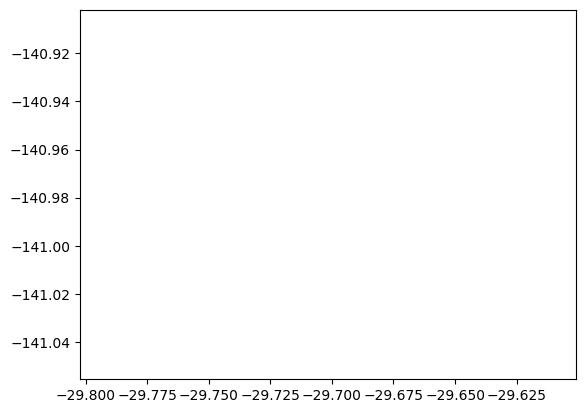

In [35]:
plt.plot(pred_coord['hycom'][...,0], pred_coord['hycom'][...,1], color='k', label=f'Predicted Path - hycom', zorder=9)


In [44]:
pred_coord['hycom'][...,1]

Array([[-140.77795, -140.77795, -140.77795, -140.77795, -140.77795,
        -140.77795, -140.77795, -140.77795, -140.77795, -140.77795,
        -140.77795, -140.77795, -140.77795, -140.77795, -140.77795,
        -140.77795, -140.77795, -140.77795, -140.77795, -140.77795,
        -140.77795, -140.77795, -140.77795, -140.77795, -140.77795,
        -140.77795, -140.77795, -140.77795, -140.77795, -140.77795,
        -140.77795, -140.77795, -140.77795, -140.77795, -140.77795,
        -140.77795, -140.77795, -140.77795, -140.77795, -140.77795,
        -140.77795, -140.77795, -140.77795, -140.77795, -140.77795,
        -140.77795, -140.77795, -140.77795, -140.77795, -140.77795,
        -140.77795, -140.77795, -140.77795, -140.77795, -140.77795,
        -140.77795, -140.77795, -140.77795, -140.77795, -140.77795,
        -140.77795, -140.77795, -140.77795, -140.77795, -140.77795,
        -140.77795, -140.77795, -140.77795, -140.77795, -140.77795,
        -140.77795, -140.77795]], dtype=float32)